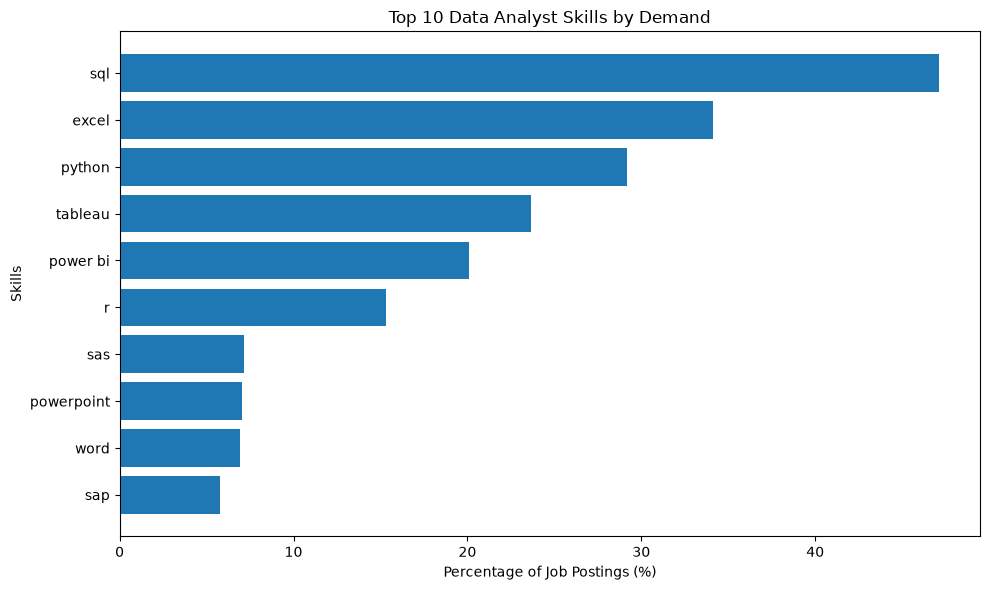

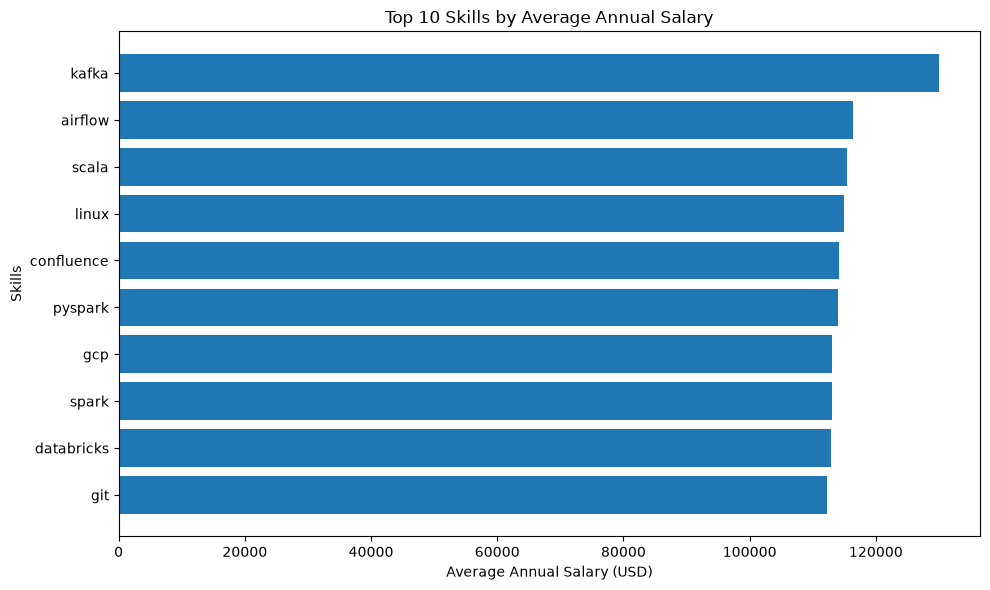

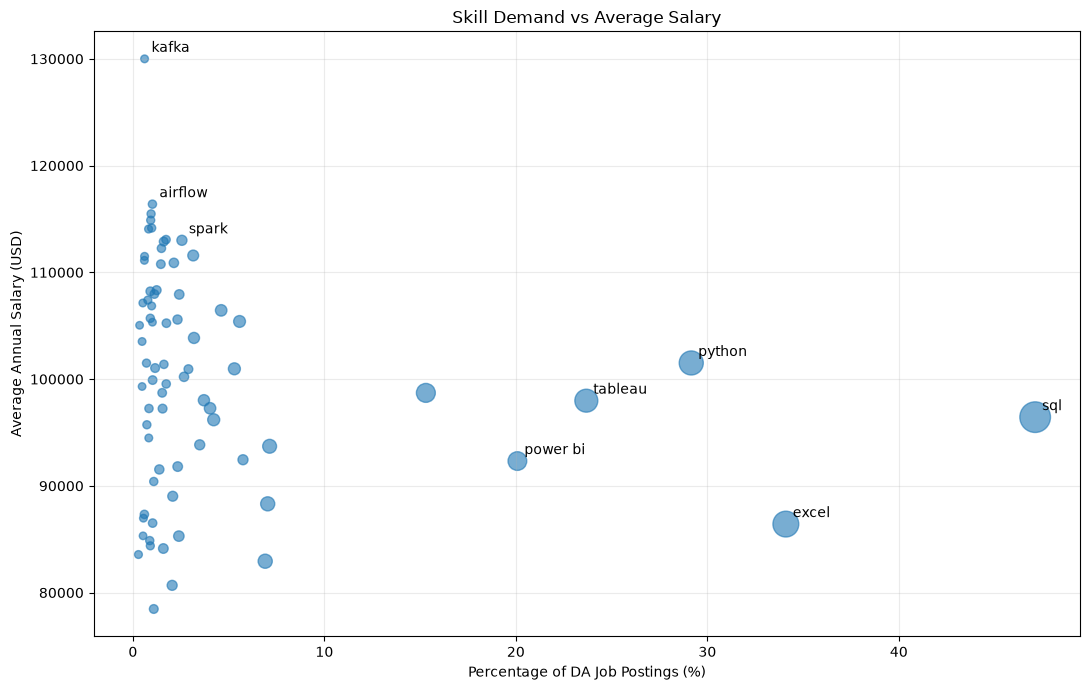

Top 5 most demanded skills:
  skills  demand_percentage  avg_salary
     sql              47.12    96435.33
   excel              34.10    86418.90
  python              29.16   101511.85
 tableau              23.68    97978.08
power bi              20.08    92323.60

Top 5 highest-paying skills:
    skills  salary_job_count  avg_salary
     kafka                40   129999.16
   airflow                71   116387.26
     scala                59   115479.53
     linux                58   114883.20
confluence                62   114153.12

Median of skill-level average salaries:
$100,573.32


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("C:/Users/Admin/Desktop/SQL_Projects/project_sql/5_most_optimal_skill.csv")

# Clean data
df["skills"] = df["skills"].str.strip().str.lower()

numeric_cols = [
    "demand_count",
    "demand_percentage",
    "salary_job_count",
    "avg_salary"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["skills"] + numeric_cols)
df = df.drop_duplicates(subset=["skills"])

# Chart 1: Top 10 most demanded skills
top_demand = df.nlargest(10, "demand_percentage")
top_demand = top_demand.sort_values("demand_percentage")

plt.figure(figsize=(10, 6))
plt.barh(top_demand["skills"], top_demand["demand_percentage"])

plt.title("Top 10 Data Analyst Skills by Demand")
plt.xlabel("Percentage of Job Postings (%)")
plt.ylabel("Skills")
plt.tight_layout()
plt.show()


# Chart 2: Top 10 highest-paying skills
top_salary = df.nlargest(10, "avg_salary")
top_salary = top_salary.sort_values("avg_salary")

plt.figure(figsize=(10, 6))
plt.barh(top_salary["skills"], top_salary["avg_salary"])

plt.title("Top 10 Skills by Average Annual Salary")
plt.xlabel("Average Annual Salary (USD)")
plt.ylabel("Skills")
plt.tight_layout()
plt.show()


# Chart 3: Demand vs Salary
plt.figure(figsize=(11, 7))

plt.scatter(
    df["demand_percentage"],
    df["avg_salary"],
    s=df["salary_job_count"] * 0.15 + 25,
    alpha=0.6
)

highlight = [
    "sql", "python", "excel",
    "tableau", "power bi",
    "kafka", "airflow", "spark"
]

for _, row in df[df["skills"].isin(highlight)].iterrows():
    plt.annotate(
        row["skills"],
        (row["demand_percentage"], row["avg_salary"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Skill Demand vs Average Salary")
plt.xlabel("Percentage of DA Job Postings (%)")
plt.ylabel("Average Annual Salary (USD)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# Generate insights
print("Top 5 most demanded skills:")
print(df.nlargest(5, "demand_percentage")[
    ["skills", "demand_percentage", "avg_salary"]
].to_string(index=False))

print("\nTop 5 highest-paying skills:")
print(df.nlargest(5, "avg_salary")[
    ["skills", "salary_job_count", "avg_salary"]
].to_string(index=False))

print("\nMedian of skill-level average salaries:")
print(f"${df['avg_salary'].median():,.2f}")